# 1. Import libraries 

In [7]:
import tensorflow as tf 
from tensorflow.keras import layers, models, datasets 
import matplotlib.pyplot as plt 
import numpy as np 
from collections import Counter

In [2]:
print(tf.config.list_physical_devices('GPU'))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [11]:
num_classes = 100

# 2. Load the dataset

In [3]:
(x_train, y_train), (x_test, y_test) = datasets.cifar100.load_data()

/mnt/d/Github/deep-learning-for-computer-vision/.venv/lib/python3.12/site-packages/keras/src/datasets/cifar.py:18: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  d = cPickle.load(f, encoding="bytes")


In [4]:
x_train 

array([[[[255, 255, 255],
         [255, 255, 255],
         [255, 255, 255],
         ...,
         [195, 205, 193],
         [212, 224, 204],
         [182, 194, 167]],

        [[255, 255, 255],
         [254, 254, 254],
         [254, 254, 254],
         ...,
         [170, 176, 150],
         [161, 168, 130],
         [146, 154, 113]],

        [[255, 255, 255],
         [254, 254, 254],
         [255, 255, 255],
         ...,
         [189, 199, 169],
         [166, 178, 130],
         [121, 133,  87]],

        ...,

        [[148, 185,  79],
         [142, 182,  57],
         [140, 179,  60],
         ...,
         [ 30,  17,   1],
         [ 65,  62,  15],
         [ 76,  77,  20]],

        [[122, 157,  66],
         [120, 155,  58],
         [126, 160,  71],
         ...,
         [ 22,  16,   3],
         [ 97, 112,  56],
         [141, 161,  87]],

        [[ 87, 122,  41],
         [ 88, 122,  39],
         [101, 134,  56],
         ...,
         [ 34,  36,  10],
        

In [5]:
x_train.shape 

(50000, 32, 32, 3)

In [6]:
y_train

array([[19],
       [29],
       [ 0],
       ...,
       [ 3],
       [ 7],
       [73]], shape=(50000, 1))

# 3. Normalize

In [9]:
x_train, x_test = x_train.astype('float32')/255.0, x_test.astype('float32')/255.0 

In [10]:
x_train 

array([[[[1.        , 1.        , 1.        ],
         [1.        , 1.        , 1.        ],
         [1.        , 1.        , 1.        ],
         ...,
         [0.7647059 , 0.8039216 , 0.75686276],
         [0.83137256, 0.8784314 , 0.8       ],
         [0.7137255 , 0.7607843 , 0.654902  ]],

        [[1.        , 1.        , 1.        ],
         [0.99607843, 0.99607843, 0.99607843],
         [0.99607843, 0.99607843, 0.99607843],
         ...,
         [0.6666667 , 0.6901961 , 0.5882353 ],
         [0.6313726 , 0.65882355, 0.50980395],
         [0.57254905, 0.6039216 , 0.44313726]],

        [[1.        , 1.        , 1.        ],
         [0.99607843, 0.99607843, 0.99607843],
         [1.        , 1.        , 1.        ],
         ...,
         [0.7411765 , 0.78039217, 0.6627451 ],
         [0.6509804 , 0.69803923, 0.50980395],
         [0.4745098 , 0.52156866, 0.34117648]],

        ...,

        [[0.5803922 , 0.7254902 , 0.30980393],
         [0.5568628 , 0.7137255 , 0.22352941]

In [12]:
y_train = tf.keras.utils.to_categorical(y_train, num_classes)
y_test = tf.keras.utils.to_categorical(y_test, num_classes)

# 4. Building the LeNet Model

In [19]:
def build_lenet(input_shape): 
    model = models.Sequential()
    # C1 Convolutional Layer 1
    model.add(layers.Conv2D(filters=6, strides=(1,1), kernel_size=(5,5), activation='tanh', input_shape=input_shape))
    # S2 Subsampling layer 2 
    model.add(layers.AveragePooling2D(pool_size=(2,2), strides=(2,2)))
    # C3 Convolutional layer 3 
    model.add(layers.Conv2D(filters=6, strides=(1,1), kernel_size=(5,5), activation='tanh'))
    # S4 Subsampling layer 4
    model.add(layers.AveragePooling2D(pool_size=(2,2), strides=(2,2)))
    # C5 Convolutional layer 5
    model.add(layers.Dense(units=120, activation='tanh'))
    # Flatten the output from the convolutional layers
    model.add(layers.Flatten())
    # F6 Fully connected layer 6
    model.add(layers.Dense(units=84, activation='tanh'))
    # Output layer with softmax activation for classification
    model.add(layers.Dense(units=num_classes, activation='softmax'))
    return model

In [16]:
len(y_test.shape)

2

In [20]:
lenet1 = build_lenet((32,32,3))
lenet1.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
epochs = 20 
history = lenet1.fit(x_train, y_train, epochs=epochs, validation_data=(x_test, y_test), batch_size=128, verbose=1)
if len(y_test.shape) != 2 or y_test.shape[1] != 100:
  y_test = tf.keras.utils.to_categorical(y_test, 100)

loss ,acc= lenet1.evaluate(x_test, y_test)
print('Accuracy : ', acc)

/mnt/d/Github/deep-learning-for-computer-vision/.venv/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
I0000 00:00:1779522314.718779    2270 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1765 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2050, pci bus id: 0000:01:00.0, compute capability: 8.6


Epoch 1/20


I0000 00:00:1779522322.310717    8508 service.cc:153] XLA service 0x75ac78004620 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1779522322.310756    8508 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 2050, Compute Capability 8.6 (Driver: 13.0.0; Runtime: 12.5.0; Toolkit: 12.5.0; DNN: 9.21.1)
I0000 00:00:1779522322.470564    8508 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1779522322.867496    8508 cuda_dnn.cc:461] Loaded cuDNN version 92101
I0000 00:00:1779522322.916620    8508 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_2002__.28
I0000 00:00:1779522324.184928    8581 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_14', 428 bytes spill stores, 272 bytes spill loads

I0000 00:00:1779522325.263433    8508 dot_search_space.cc:240] All configs wer

  7/391 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.0087 - loss: 4.6120   

I0000 00:00:1779522330.558715    8508 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


380/391 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.0711 - loss: 4.1928

I0000 00:00:1779522332.867512    8509 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_2002__.28
I0000 00:00:1779522334.260092    8786 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_14', 328 bytes spill stores, 244 bytes spill loads

I0000 00:00:1779522334.591945    8509 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


391/391 ━━━━━━━━━━━━━━━━━━━━ 28s 39ms/step - accuracy: 0.1037 - loss: 3.9834 - val_accuracy: 0.1334 - val_loss: 3.7754
Epoch 2/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.1590 - loss: 3.6562 - val_accuracy: 0.1668 - val_loss: 3.6141
Epoch 3/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.1782 - loss: 3.5337 - val_accuracy: 0.1851 - val_loss: 3.5256
Epoch 4/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.1950 - loss: 3.4483 - val_accuracy: 0.1874 - val_loss: 3.4800
Epoch 5/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.2042 - loss: 3.3873 - val_accuracy: 0.1977 - val_loss: 3.4362
Epoch 6/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.2131 - loss: 3.3346 - val_accuracy: 0.2051 - val_loss: 3.4070
Epoch 7/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.2181 - loss: 3.2976 - val_accuracy: 0.2008 - val_loss: 3.4241
Epoch 8/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.2263 - loss: 3.2572 - val_accuracy: 0.2120 - 

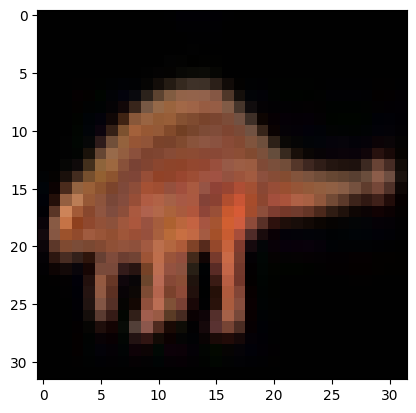

In [24]:
image_index = 8888
plt.imshow(x_test[image_index].reshape(32, 32, 3), cmap='Greys')

In [25]:
pred = lenet1.predict(x_test[image_index].reshape(1, 32, 32, 3))
print(pred.argmax())

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 995ms/step
26
